In [1]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
from torchvision import transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, ConcatDataset

from pathlib import Path

In [2]:
# dataset paths

DATASET_ROOT = Path("../dataset")

DATASET_1 = DATASET_ROOT / "dataset_1"
DATASET_2 = DATASET_ROOT / "dataset_2"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
print("Dataset 1:", DATASET_1.resolve())
print("Dataset 2:", DATASET_2.resolve())

Device: cpu
Dataset 1: D:\deepfake\dataset\dataset_1
Dataset 2: D:\deepfake\dataset\dataset_2


In [3]:
# Transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [4]:
# Dataset 1 + Dataset 2 load karo


train_dataset_1 = ImageFolder(
    DATASET_1 / "train",
    transform=train_transform
)

train_dataset_2 = ImageFolder(
    DATASET_2 / "train",
    transform=train_transform
)

val_dataset_1 = ImageFolder(
    DATASET_1 / "validation",
    transform=val_transform
)

val_dataset_2 = ImageFolder(
    DATASET_2 / "validation",
    transform=val_transform
)

In [5]:
train_dataset = ConcatDataset([
    train_dataset_1,
    train_dataset_2
])

val_dataset = ConcatDataset([
    val_dataset_1,
    val_dataset_2
])

In [6]:
print("Dataset 1 training:", len(train_dataset_1))
print("Dataset 2 training:", len(train_dataset_2))

print("Combined training:", len(train_dataset))

print("Dataset 1 validation:", len(val_dataset_1))
print("Dataset 2 validation:", len(val_dataset_2))

print("Combined validation:", len(val_dataset))

Dataset 1 training: 1428
Dataset 2 training: 3884
Combined training: 5312
Dataset 1 validation: 306
Dataset 2 validation: 547
Combined validation: 853


In [7]:
DataLoader

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Train images:", len(train_dataset))
print("Validation images:", len(val_dataset))

print("Train batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Train images: 5312
Validation images: 853
Train batches: 332
Validation batches: 54


In [8]:
# Test dataset

test_dataset_1 = ImageFolder(
    DATASET_1 / "test",
    transform=val_transform
)

test_dataset_2 = ImageFolder(
    DATASET_2 / "test",
    transform=val_transform
)

test_dataset = ConcatDataset([
    test_dataset_1,
    test_dataset_2
])

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=0
)

print("Dataset 1 test:", len(test_dataset_1))
print("Dataset 2 test:", len(test_dataset_2))
print("Total test:", len(test_dataset))

Dataset 1 test: 307
Dataset 2 test: 1126
Total test: 1433


In [9]:
# EfficientNet-B0

weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(weights=weights)

in_features = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    in_features,
    2
)

model = model.to(device)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)


In [12]:
def train_one_epoch(model, loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [13]:
def validate_one_epoch(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [14]:
EPOCHS = 10

best_val_accuracy = 0.0

train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "efficientnet_b0_dataset1_dataset2_best.pth"

for epoch in range(EPOCHS):

    print(f"\nEpoch [{epoch + 1}/{EPOCHS}]")
    print("-" * 50)

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy = validate_one_epoch(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)

    print(f"Train Loss: {train_loss:.4f}")
    print(f"Train Accuracy: {train_accuracy:.4f}")

    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")

    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print("✓ Best model saved!")

print("\nTraining completed!")
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")


Epoch [1/10]
--------------------------------------------------
Train Loss: 0.4627
Train Accuracy: 0.8151
Validation Loss: 0.4086
Validation Accuracy: 0.8042
✓ Best model saved!

Epoch [2/10]
--------------------------------------------------
Train Loss: 0.3584
Train Accuracy: 0.8417
Validation Loss: 0.3705
Validation Accuracy: 0.8019

Epoch [3/10]
--------------------------------------------------
Train Loss: 0.3255
Train Accuracy: 0.8485
Validation Loss: 0.3501
Validation Accuracy: 0.8183
✓ Best model saved!

Epoch [4/10]
--------------------------------------------------
Train Loss: 0.3090
Train Accuracy: 0.8552
Validation Loss: 0.3409
Validation Accuracy: 0.8195
✓ Best model saved!

Epoch [5/10]
--------------------------------------------------
Train Loss: 0.3075
Train Accuracy: 0.8562
Validation Loss: 0.3381
Validation Accuracy: 0.8265
✓ Best model saved!

Epoch [6/10]
--------------------------------------------------
Train Loss: 0.3075
Train Accuracy: 0.8543
Validation Loss: 0

In [15]:
# Load the best model

model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=device
    )
)

model = model.to(device)

print("Best model loaded successfully!")

Best model loaded successfully!


In [17]:
# Test Accuracy
model.eval()

correct = 0
total = 0

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, preds = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (preds == labels).sum().item()

        all_preds.extend(preds.cpu().tolist())
        all_labels.extend(labels.cpu().tolist())

test_accuracy = correct / total

print(f"Test Images: {total}")
print(f"Correct Predictions: {correct}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")

Test Images: 1433
Correct Predictions: 1288
Test Accuracy: 0.8988
Test Accuracy: 89.88%


In [18]:
# Confusion Matrix

# Assuming:
# 0 = fake
# 1 = real

tp = tn = fp = fn = 0

for actual, predicted in zip(all_labels, all_preds):

    if actual == 1 and predicted == 1:
        tp += 1
    elif actual == 0 and predicted == 0:
        tn += 1
    elif actual == 0 and predicted == 1:
        fp += 1
    elif actual == 1 and predicted == 0:
        fn += 1

print("Confusion Matrix:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

Confusion Matrix:
TN: 583
FP: 105
FN: 40
TP: 705


In [20]:
# FAKE class (0)
precision_fake = tn / (tn + fn)
recall_fake = tn / (tn + fp)
f1_fake = 2 * precision_fake * recall_fake / (precision_fake + recall_fake)

# REAL class (1)
precision_real = tp / (tp + fp)
recall_real = tp / (tp + fn)
f1_real = 2 * precision_real * recall_real / (precision_real + recall_real)

print("FAKE")
print(f"Precision: {precision_fake:.4f}")
print(f"Recall:    {recall_fake:.4f}")
print(f"F1-Score:  {f1_fake:.4f}")

print("\nREAL")
print(f"Precision: {precision_real:.4f}")
print(f"Recall:    {recall_real:.4f}")
print(f"F1-Score:  {f1_real:.4f}")

FAKE
Precision: 0.9358
Recall:    0.8474
F1-Score:  0.8894

REAL
Precision: 0.8704
Recall:    0.9463
F1-Score:  0.9068


In [21]:
# Get prediction probabilities for ROC-AUC

model.eval()

all_probs = []
all_labels_roc = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)

        # Probability of REAL class (class 1)
        probs = torch.softmax(outputs, dim=1)[:, 1]

        all_probs.extend(probs.cpu().tolist())
        all_labels_roc.extend(labels.tolist())

print("Probability predictions collected:", len(all_probs))
print("Labels collected:", len(all_labels_roc))

Probability predictions collected: 1433
Labels collected: 1433


In [22]:
import numpy as np

y_true = np.array(all_labels_roc)
y_score = np.array(all_probs)

# Sort by predicted probability from high to low
order = np.argsort(-y_score)

y_true = y_true[order]

# Total positives and negatives
P = np.sum(y_true == 1)
N = np.sum(y_true == 0)

# Calculate TPR and FPR
TP = 0
FP = 0

tpr = [0]
fpr = [0]

for label in y_true:
    if label == 1:
        TP += 1
    else:
        FP += 1

    tpr.append(TP / P)
    fpr.append(FP / N)

tpr = np.array(tpr)
fpr = np.array(fpr)

# Calculate AUC using trapezoidal rule
roc_auc = np.trapezoid(tpr, fpr)

print(f"ROC-AUC: {roc_auc:.4f}")
print(f"ROC-AUC: {roc_auc * 100:.2f}%")

ROC-AUC: 0.9698
ROC-AUC: 96.98%


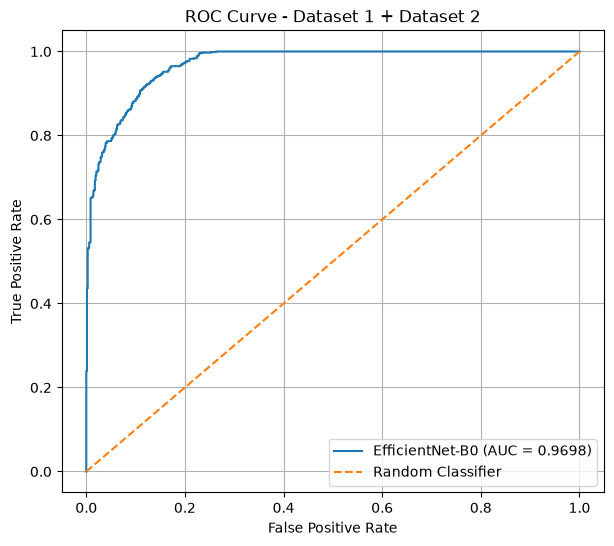

In [23]:
import matplotlib.pyplot as plt
from pathlib import Path

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    label=f"EfficientNet-B0 (AUC = {roc_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Dataset 1 + Dataset 2")

plt.legend()
plt.grid()

# Save result
results_dir = Path("../results")
results_dir.mkdir(exist_ok=True)

plt.savefig(
    results_dir / "roc_curve_dataset1_dataset2.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [24]:
from pathlib import Path
import shutil

source_model = Path("../models/efficientnet_b0_dataset1_dataset2_best.pth")
final_model = Path("../models/deepfake_efficientnet_b0_final.pth")

shutil.copy2(source_model, final_model)

print("Final model saved successfully!")
print("Path:", final_model)

Final model saved successfully!
Path: ..\models\deepfake_efficientnet_b0_final.pth


In [25]:
from PIL import Image
import torch
import torch.nn.functional as F

def predict_image(image_path):

    model.eval()

    image = Image.open(image_path).convert("RGB")

    image_tensor = val_transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)

        probabilities = F.softmax(output, dim=1)

        confidence, predicted_class = torch.max(probabilities, 1)

    class_names = ["fake", "real"]

    prediction = class_names[predicted_class.item()]
    confidence = confidence.item() * 100

    return prediction, confidence

In [28]:
from pathlib import Path

fake_folder = Path("../dataset/dataset_2/test/fake")

images = list(fake_folder.iterdir())

print("First 5 images:")
for img in images[:5]:
    print(img.name)

First 5 images:
2791.jpg
2795.jpg
2820.jpg
2829.jpg
2857.jpg


In [29]:
image_path = "../dataset/dataset_2/test/fake/2791.jpg"

prediction, confidence = predict_image(image_path)

print("Prediction:", prediction.upper())
print(f"Confidence: {confidence:.2f}%")

Prediction: FAKE
Confidence: 59.82%


In [30]:
from pathlib import Path

real_folder = Path("../dataset/dataset_2/test/real")

images = list(real_folder.iterdir())

print("First 5 REAL images:")
for img in images[:5]:
    print(img.name)

First 5 REAL images:
100.jpg
1000.jpg
1005.jpg
1008.jpg
1011.jpg


In [31]:
image_path = "../dataset/dataset_2/test/real/100.jpg"

prediction, confidence = predict_image(image_path)

print("Prediction:", prediction.upper())
print(f"Confidence: {confidence:.2f}%")

Prediction: REAL
Confidence: 95.03%


In [32]:
print(model)

EfficientNet(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): SiLU(inplace=True)
    )
    (1): Sequential(
      (0): MBConv(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
            (2): SiLU(inplace=True)
          )
          (1): SqueezeExcitation(
            (avgpool): AdaptiveAvgPool2d(output_size=1)
            (fc1): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (fc2): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (activation): SiLU(inplace=True)
            (scale_activation): Sigmoid()
          )
          